# Etapa 2 — correspondência entre imagens, NCut e votação

Este laboratório parte do `features_notebook.npz` produzido pelo notebook da
Etapa 1. O objetivo é tornar visível como CLS e patch tokens são transformados
em um score inicial de foreground.

Roteiro:

1. carregar as features da E1;
2. comparar globalmente as imagens por CLS;
3. selecionar os pares mais semelhantes;
4. calcular a saliência patch–CLS;
5. construir afinidades entre patches de um par;
6. montar o grafo combinado das duas imagens;
7. calcular o Laplaciano normalizado e o vetor de Fiedler;
8. orientar os dois lados como foreground/background;
9. repetir para os pares selecionados e acumular votos;
10. salvar `correspondence_notebook.npz`.

O notebook usa amostragem de patches por padrão para que o NCut seja rápido e
visualizável. Use `PATCH_STRIDE = 1` para trabalhar com todos os 1369 patches,
como no pipeline real.

> **⚠️ CLI do script vs. config do pipeline (mesmo padrão da Etapa 1).**
> `step2_correspondence.py` tem defaults de CLI conservadores/históricos:
> `--top_k 10`, `--orientation cls`, `--degree_alpha 0.0`, mascaramento de
> padding ligado por padrão. `run_pipeline.sh` sobrescreve três desses quatro
> valores com a config calibrada: `E2_TOP_K=60`, `E2_ORIENTATION=spatial`,
> `E2_DEGREE_ALPHA=0.10` (mascaramento de padding continua ligado nos dois).
> Ou seja, **a orientação "cls" que o próprio script chama de "comportamento
> histórico/default" não é o que a pipeline roda hoje** — isso só fica claro
> lendo `run_pipeline.sh`, não o `--help` do script. Os Passos 1–8 abaixo
> seguem a exploração original em `cls`/sem reponderação/sem máscara (mais
> simples para entender o mecanismo do zero); os blocos "Extra" mostram o
> efeito de cada peça calibrada isoladamente; e o Passo 9 final já roda com a
> config real da pipeline.
>
> Esta etapa também não cobre a E2B (`step2_bg_suppression`, supressão
> adaptativa de background recorrente) — é um script separado que consome
> `correspondence.npz` e roda só se `E2_BG_SUPPRESSION != none`. Fica de fora
> deste notebook por ora.


In [1]:
# Se necessário, descomente:
# %pip install numpy pillow matplotlib scikit-learn



In [2]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from PIL import Image
from sklearn.preprocessing import normalize as l2_normalize

plt.rcParams["figure.figsize"] = (12, 5)

FEATURES_PATH = Path("features_notebook.npz")  # saída do notebook da E1
PATCH_STRIDE = 2  # 2 = modo didático rápido; 1 = resolução integral do pipeline

# Config calibrada de run_pipeline.sh (E2_TOP_K / E2_TEMPERATURE / E2_ORIENTATION /
# E2_DEGREE_ALPHA). Os defaults "crus" do argparse de step2_correspondence.py são
# top_k=10, orientation="cls", degree_alpha=0.0 — diferentes do que a pipeline roda.
TOP_K = 60
TEMPERATURE = 0.05
ORIENTATION = "spatial"     # CLI default é "cls"; pipeline usa "spatial"
DEGREE_ALPHA = 0.10         # CLI default é 0.0
USE_CONTENT_MASK = True     # mascaramento de padding: ligado por padrão nos dois

assert FEATURES_PATH.exists(), f"Arquivo não encontrado: {FEATURES_PATH.resolve()}"


## Passo 1 — carregar a saída da Etapa 1

CLS representa a imagem globalmente. Os patch tokens representam posições da
grade, mas já contextualizadas pelo Transformer.



In [3]:
data = np.load(FEATURES_PATH, allow_pickle=True)
patch_full = data["patch_features"].astype(np.float32)
cls_features = data["cls_features"].astype(np.float32)
grid_full = tuple(int(v) for v in data["patch_grid"])
image_paths = [Path(str(p)) for p in data["image_paths"]]
resize_infos = data["resize_info"] if "resize_info" in data.files else None

N, P_full, D = patch_full.shape
H_full, W_full = grid_full
assert P_full == H_full * W_full

print(f"Imagens:             {N}")
print(f"Grade integral:      {H_full}×{W_full} = {P_full} patches")
print(f"Dimensão da feature: {D}")
print(f"CLS:                 {cls_features.shape}")
print(f"Patches:             {patch_full.shape}")



Imagens:             3
Grade integral:      37×37 = 1369 patches
Dimensão da feature: 384
CLS:                 (3, 384)
Patches:             (3, 1369, 384)


### Amostragem didática

Com `PATCH_STRIDE = 2`, escolhemos uma linha e uma coluna de patches a cada
duas. A grade 37×37 vira 19×19. Isso não muda o algoritmo, apenas reduz o
número de nós do grafo e acelera a decomposição espectral.



In [4]:
patch_grid_4d = patch_full.reshape(N, H_full, W_full, D)
patch_features = patch_grid_4d[:, ::PATCH_STRIDE, ::PATCH_STRIDE, :]
H_p, W_p = patch_features.shape[1:3]
patch_features = patch_features.reshape(N, H_p * W_p, D)
P = H_p * W_p

max_pairs = N * (N - 1) // 2
TOP_K = min(TOP_K, max_pairs)

print(f"Grade usada:         {H_p}×{W_p} = {P} patches")
print(f"Nós por grafo:       {2 * P}")
print(f"Pares selecionados:  {TOP_K} de {max_pairs} possíveis")

Grade usada:         19×19 = 361 patches
Nós por grafo:       722
Pares selecionados:  3 de 3 possíveis


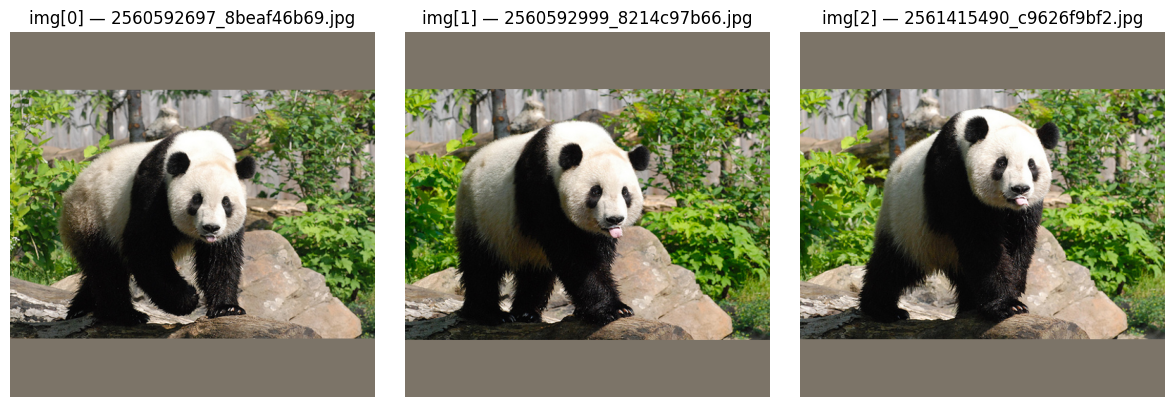

In [5]:
def build_canvas(path: Path, info):
    """Reconstrói o canvas keep_ar salvo pela E1 para alinhar os mapas."""
    image = Image.open(path).convert("RGB")
    if info is None:
        return image.resize((518, 518), Image.Resampling.BICUBIC)
    new_h, new_w, pad_top, pad_left, canvas_h, canvas_w = map(int, info)
    resized = image.resize((new_w, new_h), Image.Resampling.BICUBIC)
    mean = (0.485, 0.456, 0.406)
    pad_color = tuple(int(round(v * 255)) for v in mean)
    canvas = Image.new("RGB", (canvas_w, canvas_h), pad_color)
    canvas.paste(resized, (pad_left, pad_top))
    return canvas


canvases = [
    build_canvas(path, resize_infos[i] if resize_infos is not None else None)
    for i, path in enumerate(image_paths)
]

fig, axes = plt.subplots(1, N, figsize=(4 * N, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.imshow(canvases[i])
    ax.set_title(f"img[{i}] — {image_paths[i].name}")
    ax.axis("off")
plt.tight_layout()



### Extra — máscara de conteúdo (padding da Etapa 1)

Se a Etapa 1 rodou com `--resize keep_ar`, `resize_info` diz exatamente quais
patches caem na faixa de padding. `step2_correspondence.py` usa isso por
padrão para **excluir** esses patches do grafo de afinidade e da orientação
FG/BG de cada par, e força o voto final deles a 0 (background) — sem essa
máscara, a entrada quase constante do padding gera afinidade cross-image
artificialmente alta entre imagens, competindo por espaço no NCut com os
patches de conteúdo real (o mesmo bug de mascaramento já corrigido na Etapa 1
e nos analisadores de ablation).

A função abaixo é a mesma `compute_content_mask()` de `step2_correspondence.py`,
só adaptada para a grade (possivelmente reamostrada por `PATCH_STRIDE`) deste
notebook.


Total mascarado: 26.3% dos patches (todas as imagens)


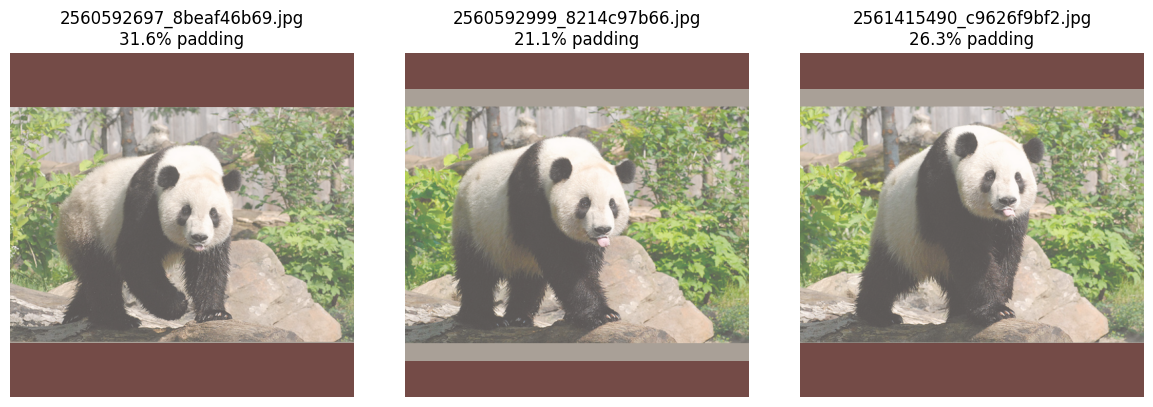

In [6]:
def compute_content_mask(resize_info, patch_grid):
    """Réplica de compute_content_mask() do step2_correspondence.py.

    Um patch é considerado "conteúdo" se tem QUALQUER interseção com a região
    redimensionada dentro do canvas (não só o centro) — mesmo critério usado
    nos scripts de ablation para alinhar o GT.
    """
    if resize_info is None:
        return None

    H_p_, W_p_ = patch_grid
    N_ = resize_info.shape[0]
    canvas_h, canvas_w = int(resize_info[0, 4]), int(resize_info[0, 5])
    patch_h = canvas_h / H_p_
    patch_w = canvas_w / W_p_

    row_starts = np.arange(H_p_) * patch_h
    col_starts = np.arange(W_p_) * patch_w
    row_ends = row_starts + patch_h
    col_ends = col_starts + patch_w

    masks = np.zeros((N_, H_p_, W_p_), dtype=bool)
    for i in range(N_):
        resized_h, resized_w, pad_top, pad_left, _, _ = [int(x) for x in resize_info[i]]
        content_row = (row_ends > pad_top) & (row_starts < pad_top + resized_h)
        content_col = (col_ends > pad_left) & (col_starts < pad_left + resized_w)
        masks[i] = content_row[:, None] & content_col[None, :]

    return masks.reshape(N_, -1)


content_mask = compute_content_mask(resize_infos, (H_p, W_p)) if USE_CONTENT_MASK else None

if content_mask is not None:
    fig, axes = plt.subplots(1, N, figsize=(4 * N, 4), squeeze=False)
    for i, path in enumerate(image_paths):
        m2d = content_mask[i].reshape(H_p, W_p)
        axes[0, i].imshow(canvases[i])
        axes[0, i].imshow(
            ~m2d, extent=(0, canvases[i].width, canvases[i].height, 0),
            cmap="Reds", alpha=0.35, vmin=0, vmax=1, interpolation="nearest",
        )
        axes[0, i].set_title(f"{path.name}\n{(1 - m2d.mean()):.1%} padding")
        axes[0, i].axis("off")
    plt.tight_layout()
    print(f"Total mascarado: {(1 - content_mask.mean()):.1%} dos patches (todas as imagens)")
else:
    print("Sem resize_info (Etapa 1 rodou em modo \'square\') ou USE_CONTENT_MASK=False — nada a mascarar.")


## Passo 2 — similaridade global pelos tokens CLS

Normalizamos os CLS e calculamos todos os produtos internos. Como a norma é
1, o produto interno equivale à similaridade por cosseno.



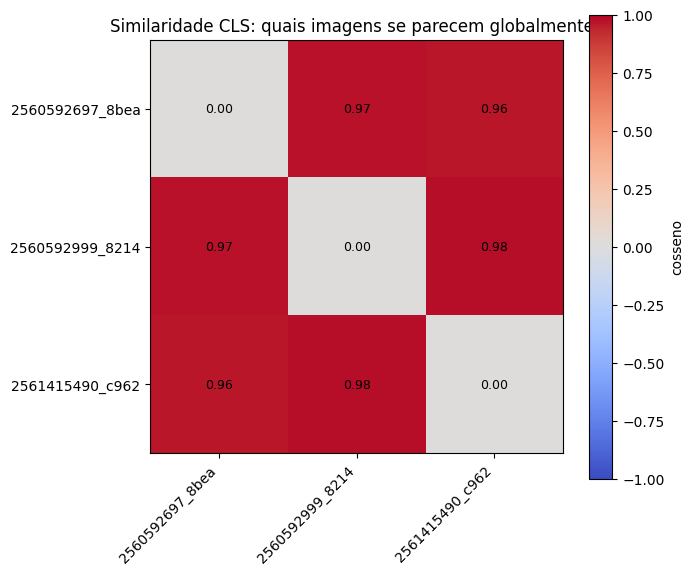

In [7]:
cls_l2 = l2_normalize(cls_features, axis=1)
cls_sim = cls_l2 @ cls_l2.T
np.fill_diagonal(cls_sim, 0.0)  # o pipeline não forma pares de uma imagem consigo

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cls_sim, cmap="coolwarm", vmin=-1, vmax=1)
labels = [p.stem[:15] for p in image_paths]
ax.set_xticks(range(N), labels, rotation=45, ha="right")
ax.set_yticks(range(N), labels)
for i in range(N):
    for j in range(N):
        ax.text(j, i, f"{cls_sim[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Similaridade CLS: quais imagens se parecem globalmente?")
fig.colorbar(im, ax=ax, label="cosseno")
plt.tight_layout()



## Passo 3 — selecionar os pares mais semelhantes

A E2 evita processar necessariamente todos os pares. Ela ordena as combinações
por similaridade CLS e conserva as `TOP_K` primeiras.



1. img[1] × img[2]  CLS sim=0.9792
2. img[0] × img[1]  CLS sim=0.9746
3. img[0] × img[2]  CLS sim=0.9622


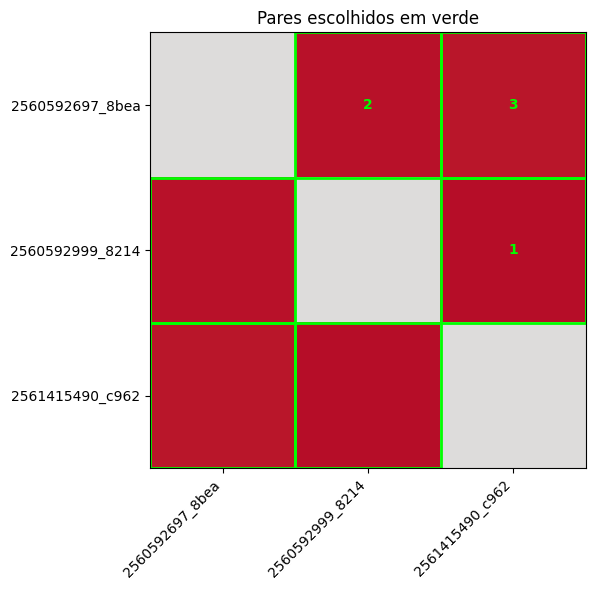

In [8]:
all_pairs = [(i, j, float(cls_sim[i, j])) for i in range(N) for j in range(i + 1, N)]
all_pairs.sort(key=lambda item: item[2], reverse=True)
top_pairs = all_pairs[:TOP_K]

for rank, (i, j, score) in enumerate(top_pairs, 1):
    print(f"{rank}. img[{i}] × img[{j}]  CLS sim={score:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cls_sim, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(N), labels, rotation=45, ha="right")
ax.set_yticks(range(N), labels)
for rank, (i, j, _) in enumerate(top_pairs, 1):
    for row, col in [(i, j), (j, i)]:
        ax.add_patch(mpatches.Rectangle((col - .5, row - .5), 1, 1, fill=False,
                                        edgecolor="lime", linewidth=2))
    ax.text(j, i, str(rank), color="lime", ha="center", va="center", fontweight="bold")
ax.set_title("Pares escolhidos em verde")
plt.tight_layout()



## Passo 4 — saliência de cada patch em relação ao CLS

Para cada imagem, calculamos:

\[
s_{i,p}=\cos(\mathrm{CLS}_i,\mathrm{patch}_{i,p})
\]

Esse mapa não é uma máscara verdadeira. Ele mede quanto cada região está
alinhada com a representação global da própria imagem. Mais tarde, será usado
somente para decidir qual lado do corte parece mais foreground.



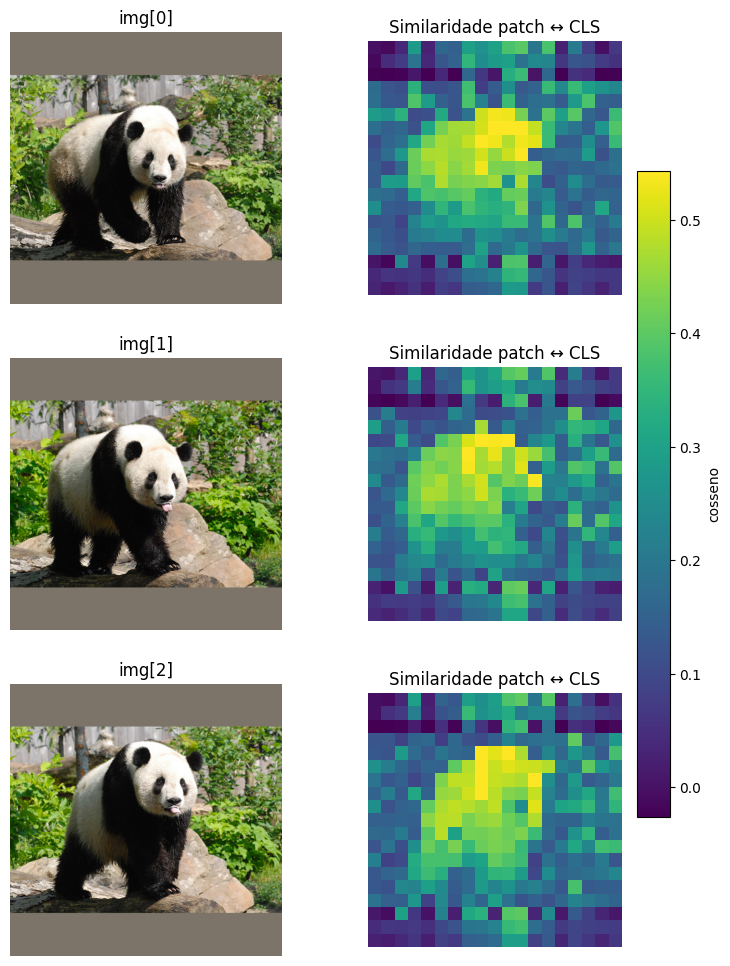

In [9]:
patch_l2 = l2_normalize(patch_features.reshape(-1, D), axis=1).reshape(N, P, D)
cls_saliency = np.einsum("nd,npd->np", cls_l2, patch_l2)
cls_saliency_2d = cls_saliency.reshape(N, H_p, W_p)

fig, axes = plt.subplots(N, 2, figsize=(9, 4 * N), squeeze=False)
vmin, vmax = np.percentile(cls_saliency, [1, 99])
for i in range(N):
    axes[i, 0].imshow(canvases[i]); axes[i, 0].set_title(f"img[{i}]")
    heat = axes[i, 1].imshow(cls_saliency_2d[i], cmap="viridis", vmin=vmin, vmax=vmax,
                             interpolation="nearest")
    axes[i, 1].set_title("Similaridade patch ↔ CLS")
    for ax in axes[i]: ax.axis("off")
fig.colorbar(heat, ax=axes[:, 1], shrink=.7, label="cosseno")
plt.show()



## Passo 5 — afinidade entre patches de duas imagens

Vamos abrir o par mais semelhante. `W_ij[a,b]` mede a similaridade entre o
patch `a` da imagem `i` e o patch `b` da imagem `j`.



Formato de W_ij: (361, 361)
Menor / média / maior: -0.1398175 0.22954585 0.9991017


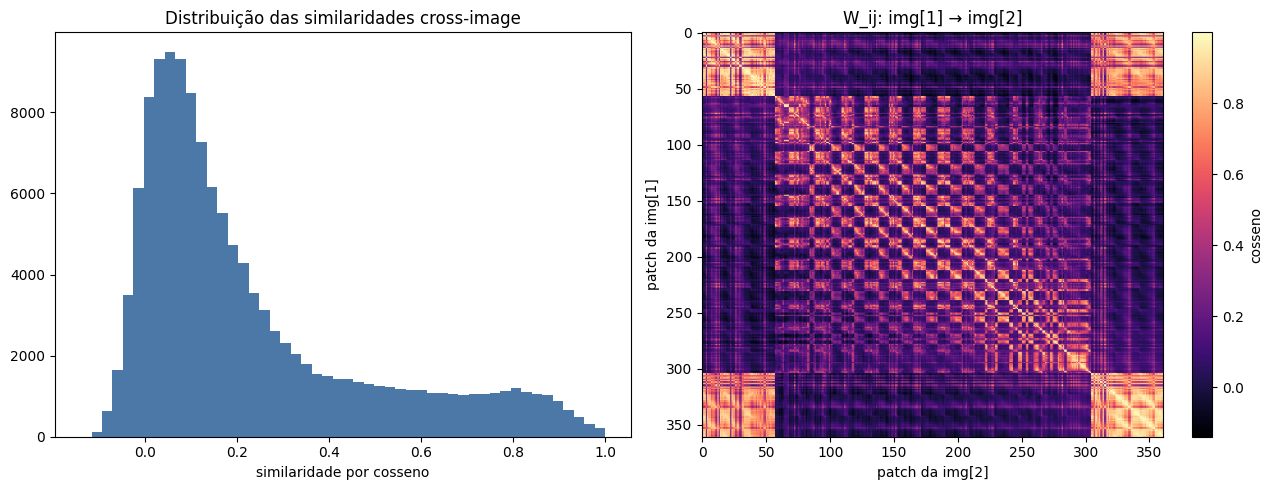

In [10]:
best_i, best_j, best_cls_score = top_pairs[0]
fi = patch_l2[best_i]
fj = patch_l2[best_j]

W_ij_cos = fi @ fj.T

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(W_ij_cos.ravel(), bins=50, color="#4c78a8")
axes[0].set_title("Distribuição das similaridades cross-image")
axes[0].set_xlabel("similaridade por cosseno")
matrix_view = axes[1].imshow(W_ij_cos, cmap="magma", aspect="auto")
axes[1].set_title(f"W_ij: img[{best_i}] → img[{best_j}]")
axes[1].set_xlabel(f"patch da img[{best_j}]")
axes[1].set_ylabel(f"patch da img[{best_i}]")
fig.colorbar(matrix_view, ax=axes[1], label="cosseno")
plt.tight_layout()

print("Formato de W_ij:", W_ij_cos.shape)
print("Menor / média / maior:", W_ij_cos.min(), W_ij_cos.mean(), W_ij_cos.max())



### Enxergar algumas correspondências

Para patches de consulta da primeira imagem, marcamos o patch mais semelhante
na segunda. As linhas não são parte do pipeline; são apenas uma visualização.



consulta ( 6, 6) → match ( 5, 7), sim=0.9463
consulta ( 9, 9) → match ( 8,10), sim=0.7917
consulta (12,12) → match (12,12), sim=0.9449


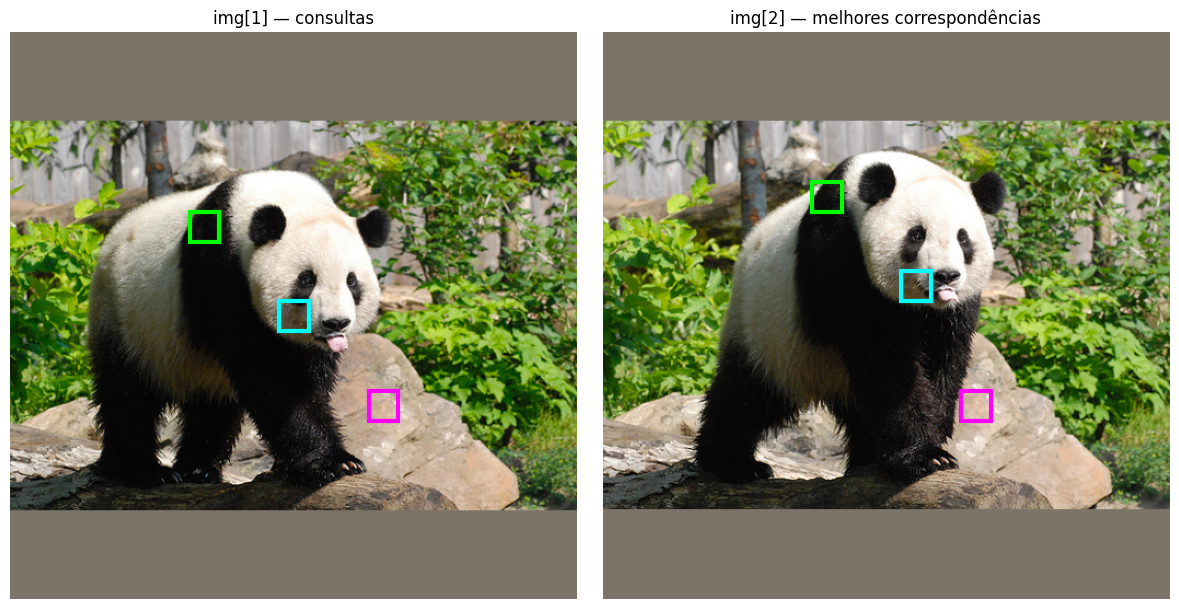

In [11]:
query_positions = [
    (H_p // 3, W_p // 3),
    (H_p // 2, W_p // 2),
    (2 * H_p // 3, 2 * W_p // 3),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(canvases[best_i]); axes[0].set_title(f"img[{best_i}] — consultas")
axes[1].imshow(canvases[best_j]); axes[1].set_title(f"img[{best_j}] — melhores correspondências")

canvas_w, canvas_h = canvases[0].size
cell_w, cell_h = canvas_w / W_p, canvas_h / H_p
colors = ["lime", "cyan", "magenta"]
for (row, col), color in zip(query_positions, colors):
    q = row * W_p + col
    match = int(np.argmax(W_ij_cos[q]))
    mr, mc = divmod(match, W_p)
    for ax, r, c in [(axes[0], row, col), (axes[1], mr, mc)]:
        ax.add_patch(mpatches.Rectangle((c * cell_w, r * cell_h), cell_w, cell_h,
                                        fill=False, edgecolor=color, linewidth=3))
    print(f"consulta ({row:2},{col:2}) → match ({mr:2},{mc:2}), sim={W_ij_cos[q, match]:.4f}")
for ax in axes: ax.axis("off")
plt.tight_layout()



## O papel da temperatura

O pipeline transforma as similaridades em afinidades não negativas:

\[
W=\exp(\mathrm{sim}/T)
\]

Temperaturas baixas ampliam fortemente a diferença entre correspondências
medianas e fortes. Isso não é uma softmax: as linhas não são normalizadas para
somar 1.



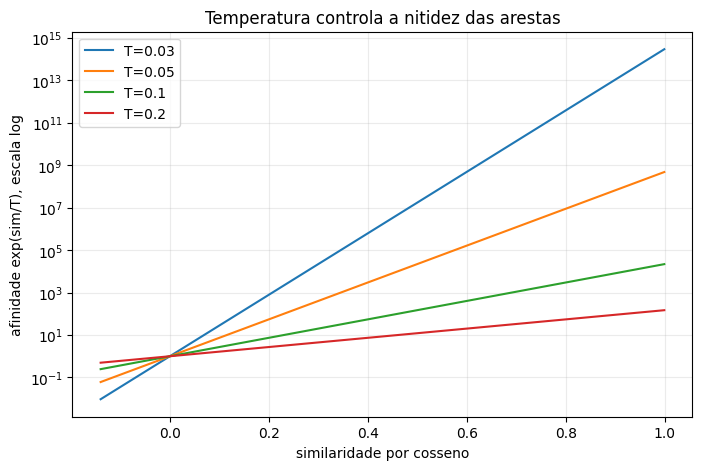

In [12]:
similarity_axis = np.linspace(max(-.2, W_ij_cos.min()), W_ij_cos.max(), 300)

fig, ax = plt.subplots(figsize=(8, 5))
for T in [0.03, 0.05, 0.10, 0.20]:
    ax.semilogy(similarity_axis, np.exp(similarity_axis / T), label=f"T={T}")
ax.set_xlabel("similaridade por cosseno")
ax.set_ylabel("afinidade exp(sim/T), escala log")
ax.set_title("Temperatura controla a nitidez das arestas")
ax.legend(); ax.grid(alpha=.25)
plt.show()



## Passo 6 — montar o grafo combinado

O grafo possui patches das duas imagens como nós:

```text
              destino
             img i     img j
origem img i  W_ii      W_ij
       img j  W_ijᵀ     W_jj
```

Os blocos diagonais representam coerência dentro de cada imagem. Os blocos
fora da diagonal representam correspondências entre imagens.



Formato do grafo: (722, 722)


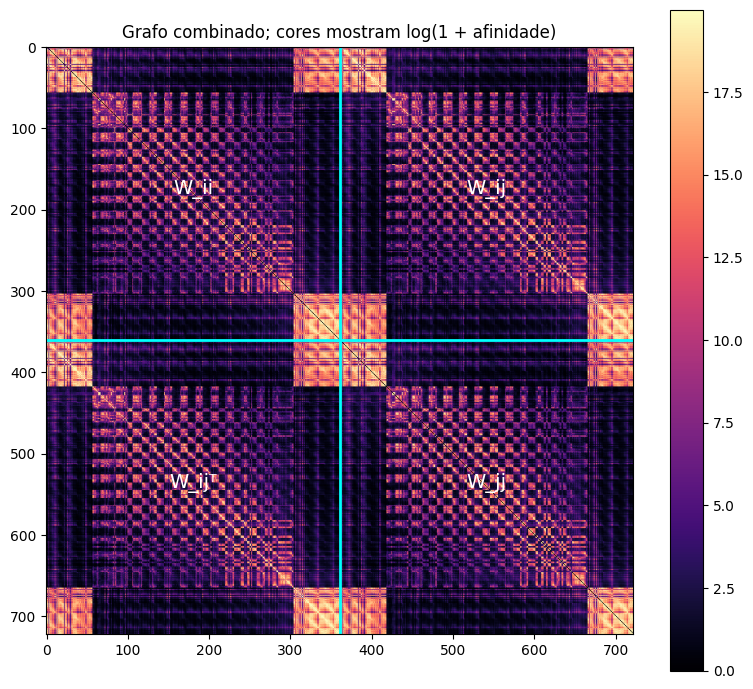

In [13]:
def build_pair_affinity(feat_i, feat_j, temperature=TEMPERATURE, degree_alpha=0.0):
    fi = l2_normalize(feat_i, axis=1)
    fj = l2_normalize(feat_j, axis=1)
    W_ii = np.exp((fi @ fi.T) / temperature)
    W_jj = np.exp((fj @ fj.T) / temperature)
    W_ij = np.exp((fi @ fj.T) / temperature)
    np.fill_diagonal(W_ii, 0.0)
    np.fill_diagonal(W_jj, 0.0)
    W = np.block([[W_ii, W_ij], [W_ij.T, W_jj]]).astype(np.float32)

    # Reponderação por grau pré-NCut (W'_ij = W_ij / (d_i d_j)^alpha).
    # alpha=0.0 preserva bit-a-bit o comportamento original desta função.
    if degree_alpha > 0.0:
        d = np.maximum(W.sum(axis=1), 1e-12)
        scale = np.power(d, degree_alpha)
        W = W / (scale[:, None] * scale[None, :])
        W = 0.5 * (W + W.T)  # garante simetria numérica

    return W


W = build_pair_affinity(patch_features[best_i], patch_features[best_j])

fig, ax = plt.subplots(figsize=(8, 7))
view = ax.imshow(np.log1p(W), cmap="magma")
ax.axvline(P - .5, color="cyan", linewidth=2)
ax.axhline(P - .5, color="cyan", linewidth=2)
ax.text(P / 2, P / 2, "W_ii", color="white", ha="center", fontsize=14)
ax.text(1.5 * P, P / 2, "W_ij", color="white", ha="center", fontsize=14)
ax.text(P / 2, 1.5 * P, "W_ijᵀ", color="white", ha="center", fontsize=14)
ax.text(1.5 * P, 1.5 * P, "W_jj", color="white", ha="center", fontsize=14)
ax.set_title("Grafo combinado; cores mostram log(1 + afinidade)")
fig.colorbar(view, ax=ax)
plt.tight_layout()

print("Formato do grafo:", W.shape)


### Extra — reponderação por grau (`degree_alpha`)

`run_pipeline.sh` aplica, antes do NCut:

\[
W'_{ij} = \frac{W_{ij}}{(d_i\, d_j)^{\alpha}}, \quad \alpha = 0.10
\]

onde `d` é o grau de cada nó na matriz `W` original (soma da linha). Isso
suaviza a dominância de nós com grau muito alto — tipicamente regiões de
fundo repetitivo, que tendem a ter afinidade alta com muitos outros patches —
antes de o NCut normalizar de novo internamente. O sweep de ablação (mesmas 6
classes de validação do iCoseg) encontrou: `alpha=0.00 → IoU 0.6827`,
`alpha=0.10 → IoU 0.7080` (melhor), `alpha=0.25 → IoU 0.6949`,
`alpha=0.50 → IoU 0.6557` — por isso `0.10` é o default da pipeline, não `0.0`
(default do CLI) nem `0.5` (normalização simétrica completa).


Desvio padrão do grau, alpha=0.0:   3.2208678e+09
Desvio padrão do grau, alpha=0.1:  3.192448e+07


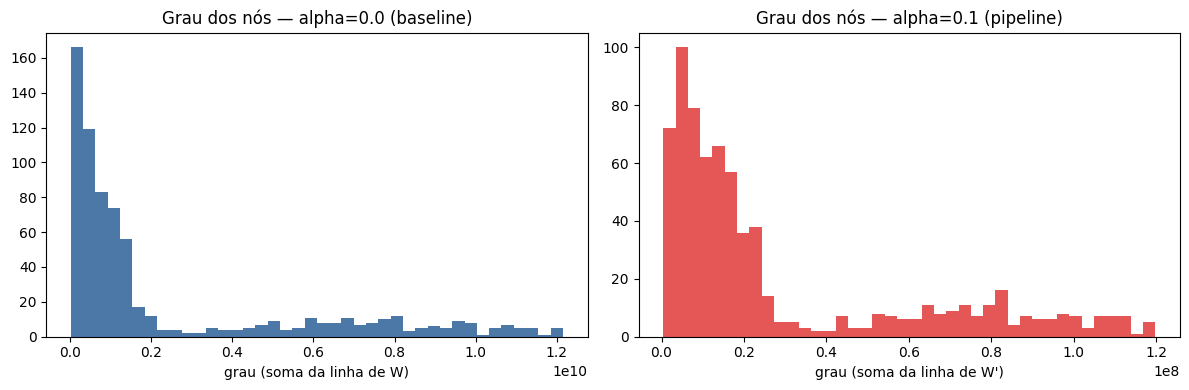

In [14]:
W_alpha = build_pair_affinity(
    patch_features[best_i], patch_features[best_j],
    temperature=TEMPERATURE, degree_alpha=DEGREE_ALPHA,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(W.sum(axis=1), bins=40, color="#4c78a8")
axes[0].set_title("Grau dos nós — alpha=0.0 (baseline)")
axes[0].set_xlabel("grau (soma da linha de W)")
axes[1].hist(W_alpha.sum(axis=1), bins=40, color="#e45756")
axes[1].set_title(f"Grau dos nós — alpha={DEGREE_ALPHA} (pipeline)")
axes[1].set_xlabel("grau (soma da linha de W')")
plt.tight_layout()

print("Desvio padrão do grau, alpha=0.0:  ", W.sum(axis=1).std())
print(f"Desvio padrão do grau, alpha={DEGREE_ALPHA}: ", W_alpha.sum(axis=1).std())


## Passo 7 — Laplaciano normalizado e vetor de Fiedler

O grau de um nó é a soma de suas afinidades:

\[
d_i=\sum_j W_{ij}
\]

O Laplaciano normalizado é:

\[
L_{sym}=I-D^{-1/2}WD^{-1/2}
\]

O primeiro autovetor representa a solução trivial. O segundo, chamado vetor
de Fiedler, fornece uma partição do grafo em dois grupos coerentes.



Decomposição concluída em 6.76 s
Primeiros autovalores: [-1.7770649e-09  2.3244917e-04  1.1047970e-03  2.1638721e-03
  7.4359276e-03  1.0111803e-02]


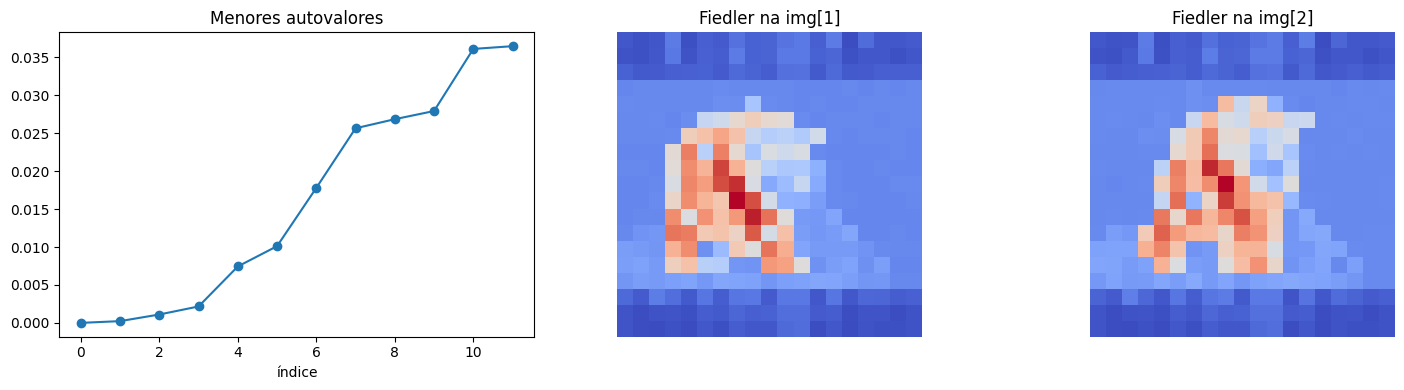

In [15]:
def normalized_cut(W):
    degree = W.sum(axis=1)
    inv_sqrt = 1.0 / np.sqrt(np.maximum(degree, 1e-8))
    L_sym = np.eye(W.shape[0], dtype=np.float32) - inv_sqrt[:, None] * W * inv_sqrt[None, :]
    eigenvalues, eigenvectors = np.linalg.eigh(L_sym)
    return eigenvalues, eigenvectors


start = time.time()
eigenvalues, eigenvectors = normalized_cut(W)
fiedler = eigenvectors[:, 1]
print(f"Decomposição concluída em {time.time() - start:.2f} s")
print("Primeiros autovalores:", eigenvalues[:6])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(eigenvalues[:12], "o-")
axes[0].set_title("Menores autovalores")
axes[0].set_xlabel("índice")
axes[1].imshow(fiedler[:P].reshape(H_p, W_p), cmap="coolwarm", interpolation="nearest")
axes[1].set_title(f"Fiedler na img[{best_i}]")
axes[2].imshow(fiedler[P:].reshape(H_p, W_p), cmap="coolwarm", interpolation="nearest")
axes[2].set_title(f"Fiedler na img[{best_j}]")
for ax in axes[1:]: ax.axis("off")
plt.tight_layout()



As cores azul e vermelha indicam os dois lados do corte. O sinal do autovetor
é arbitrário: multiplicar todo o vetor por −1 fornece a mesma partição. Por
isso, o NCut sozinho não sabe qual lado é objeto e qual é fundo.



## Passo 8 — orientar o corte como foreground/background

Dividimos pelo valor mediano do Fiedler. Depois calculamos a saliência CLS
média nos dois lados. O lado com maior média recebe o rótulo foreground.



Saliência média do lado positivo: 0.2861
Saliência média do lado negativo: 0.1618


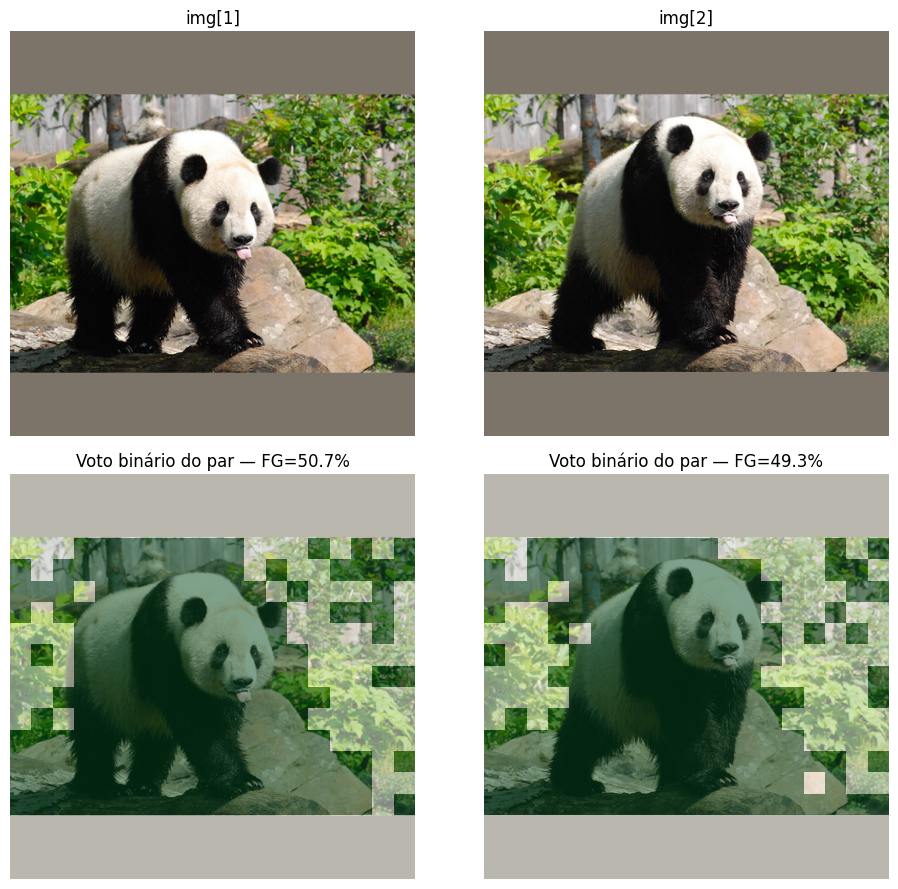

In [16]:
def orient_partition(fiedler, saliency_i, saliency_j):
    saliency_all = np.concatenate([saliency_i, saliency_j])
    side_positive = fiedler > np.median(fiedler)
    mean_positive = saliency_all[side_positive].mean() if side_positive.any() else 0.0
    mean_negative = saliency_all[~side_positive].mean() if (~side_positive).any() else 0.0
    foreground = side_positive if mean_positive >= mean_negative else ~side_positive
    return foreground, mean_positive, mean_negative


fg_mask, sal_pos, sal_neg = orient_partition(
    fiedler, cls_saliency[best_i], cls_saliency[best_j]
)
fg_i = fg_mask[:P].reshape(H_p, W_p)
fg_j = fg_mask[P:].reshape(H_p, W_p)

print(f"Saliência média do lado positivo: {sal_pos:.4f}")
print(f"Saliência média do lado negativo: {sal_neg:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for col, (idx, mask) in enumerate([(best_i, fg_i), (best_j, fg_j)]):
    axes[0, col].imshow(canvases[idx]); axes[0, col].set_title(f"img[{idx}]")
    axes[1, col].imshow(canvases[idx])
    axes[1, col].imshow(mask, extent=(0, canvases[idx].width, canvases[idx].height, 0),
                        cmap="Greens", vmin=0, vmax=1, alpha=.5, interpolation="nearest")
    axes[1, col].set_title(f"Voto binário do par — FG={mask.mean()*100:.1f}%")
    for ax in axes[:, col]: ax.axis("off")
plt.tight_layout()


### Extra — orientação espacial (o default real da pipeline)

`step2_correspondence.py` chama `orientation='cls'` de "comportamento
histórico/default", mas `run_pipeline.sh` sobrescreve para `spatial`:
escolhe, para o par inteiro, o lado mais **central e compacto** nas duas
imagens (em vez do lado com maior saliência CLS média). Comparamos abaixo as
duas orientações no mesmo par e no mesmo corte NCut (`fiedler` já calculado
no Passo 7) — só a REGRA de qual lado vira FG muda.


Concordância cls vs. spatial — img[1]: 100.0%  |  img[2]: 100.0%
(100% = as duas heurísticas escolheram o mesmo lado nesse par; divergências grandes
 são o tipo de caso que motivou testar 'spatial' como alternativa a 'cls'.)


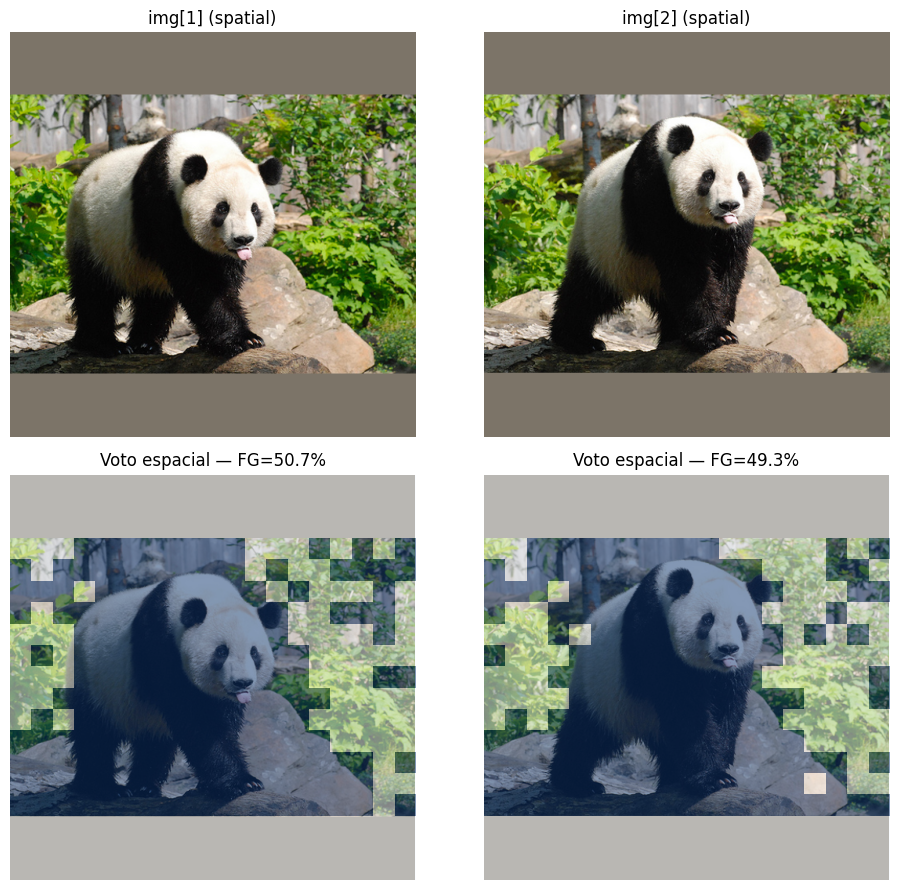

In [17]:
def _spatial_score_for_image_side(side_mask, patch_indices, patch_grid):
    """Réplica de _spatial_score_for_image_side() do step2_correspondence.py."""
    if not side_mask.any():
        return 0.0
    H_p_, W_p_ = patch_grid
    rows = (patch_indices // W_p_).astype(np.float32) / max(H_p_ - 1, 1)
    cols = (patch_indices % W_p_).astype(np.float32) / max(W_p_ - 1, 1)
    rows_sel, cols_sel = rows[side_mask], cols[side_mask]
    max_dist = np.sqrt(0.5 ** 2 + 0.5 ** 2)
    dist_center = np.sqrt((rows_sel - 0.5) ** 2 + (cols_sel - 0.5) ** 2) / max_dist
    centrality = 1.0 - float(dist_center.mean())
    std_r, std_c = float(rows_sel.std()), float(cols_sel.std())
    compactness = 1.0 - min(((std_r + std_c) / 2.0) / 0.289, 1.0)
    return float(np.sqrt(max(centrality, 0.0) * max(compactness, 0.0)))


def orient_partition_spatial(fiedler, n_patches_i, idx_i, idx_j, patch_grid):
    """Réplica de orient_partition_spatial() do step2_correspondence.py —
    default real da pipeline (E2_ORIENTATION=spatial)."""
    side_pos = fiedler > np.median(fiedler)
    pos_i, pos_j = side_pos[:n_patches_i], side_pos[n_patches_i:]
    score_pos = 0.5 * (
        _spatial_score_for_image_side(pos_i, idx_i, patch_grid)
        + _spatial_score_for_image_side(pos_j, idx_j, patch_grid)
    )
    score_neg = 0.5 * (
        _spatial_score_for_image_side(~pos_i, idx_i, patch_grid)
        + _spatial_score_for_image_side(~pos_j, idx_j, patch_grid)
    )
    return side_pos if score_pos >= score_neg else ~side_pos


idx_full = np.arange(P)
fg_mask_spatial = orient_partition_spatial(fiedler, P, idx_full, idx_full, (H_p, W_p))
fg_i_spatial = fg_mask_spatial[:P].reshape(H_p, W_p)
fg_j_spatial = fg_mask_spatial[P:].reshape(H_p, W_p)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for col, (idx, mask) in enumerate([(best_i, fg_i_spatial), (best_j, fg_j_spatial)]):
    axes[0, col].imshow(canvases[idx]); axes[0, col].set_title(f"img[{idx}] (spatial)")
    axes[1, col].imshow(canvases[idx])
    axes[1, col].imshow(mask, extent=(0, canvases[idx].width, canvases[idx].height, 0),
                        cmap="Blues", vmin=0, vmax=1, alpha=.5, interpolation="nearest")
    axes[1, col].set_title(f"Voto espacial — FG={mask.mean()*100:.1f}%")
    for ax in axes[:, col]: ax.axis("off")
plt.tight_layout()

agree_i = (fg_i.flatten() == fg_mask_spatial[:P]).mean()
agree_j = (fg_j.flatten() == fg_mask_spatial[P:]).mean()
print(f"Concordância cls vs. spatial — img[{best_i}]: {agree_i:.1%}  |  img[{best_j}]: {agree_j:.1%}")
print("(100% = as duas heurísticas escolheram o mesmo lado nesse par; divergências grandes")
print(" são o tipo de caso que motivou testar \'spatial\' como alternativa a \'cls\'.)")


### Extra — o que a máscara de conteúdo muda neste par

O Passo 8 acima não usou máscara de padding (chamou `build_pair_affinity` com
todos os `P` patches, incluindo padding se a imagem tiver). Se `content_mask`
existir, dá para checar quantos patches de padding foram votados FG só por
"aparência" (entrada quase constante, similar entre imagens):


In [18]:
if content_mask is not None:
    pad_i = ~content_mask[best_i].reshape(H_p, W_p)
    pad_j = ~content_mask[best_j].reshape(H_p, W_p)
    leak_i = int((pad_i & (fg_i > 0)).sum())
    leak_j = int((pad_j & (fg_j > 0)).sum())
    print(f"Sem máscara: img[{best_i}] teve {leak_i} patch(es) de padding votado(s) como FG.")
    print(f"Sem máscara: img[{best_j}] teve {leak_j} patch(es) de padding votado(s) como FG.")
    print("Com a máscara ligada (Passo 9), esses patches nunca entram no grafo e o voto")
    print("final deles é forçado a 0 — não competem mais por FG.")
else:
    print("Sem resize_info (Etapa 1 rodou em modo 'square') — não há padding para vazar.")


Sem máscara: img[1] teve 0 patch(es) de padding votado(s) como FG.
Sem máscara: img[2] teve 0 patch(es) de padding votado(s) como FG.
Com a máscara ligada (Passo 9), esses patches nunca entram no grafo e o voto
final deles é forçado a 0 — não competem mais por FG.


Esse resultado ainda não é a máscara final. É apenas o voto emitido por um
par. Outro par pode produzir uma partição diferente.



## Passo 9 — processar todos os pares e acumular votos (config real da pipeline)

Cada voto é ponderado pela similaridade CLS do par. Para uma imagem, o score
de um patch é:

\[
\mathrm{fg\_score}_{i,p}=
\frac{\sum_k w_k v_{k,i,p}}{\sum_k w_k}
\]

onde `v` vale 0 ou 1 e `w` é a similaridade CLS não negativa.

A partir daqui o notebook para de usar a versão simplificada dos Passos 5–8
(`orientation='cls'`, sem máscara de padding, sem reponderação por grau) e passa
a usar exatamente a config de `run_pipeline.sh`: `ORIENTATION`, `DEGREE_ALPHA` e
`USE_CONTENT_MASK` definidos no topo do notebook. `fg_scores` calculado aqui é
o que corresponde ao `correspondence.npz` real, não mais um exemplo didático
isolado.


In [19]:
def process_pair(i, j, *, content_mask=content_mask, orientation=ORIENTATION,
                  degree_alpha=DEGREE_ALPHA):
    """Réplica do laço principal de run_correspondence() em step2_correspondence.py:
    restringe a patches de conteúdo (se content_mask existir), monta o grafo já
    com degree_alpha, e orienta FG/BG pelo método configurado. Reusa
    orient_partition_spatial() definida no bloco "Extra" do Passo 8."""
    feat_i, feat_j = patch_features[i], patch_features[j]
    sal_i, sal_j = cls_saliency[i], cls_saliency[j]

    if content_mask is not None:
        idx_i = np.flatnonzero(content_mask[i])
        idx_j = np.flatnonzero(content_mask[j])
        if idx_i.size == 0 or idx_j.size == 0:
            idx_i, idx_j = np.arange(P), np.arange(P)
    else:
        idx_i, idx_j = np.arange(P), np.arange(P)

    feat_i_c, feat_j_c = feat_i[idx_i], feat_j[idx_j]
    sal_i_c, sal_j_c = sal_i[idx_i], sal_j[idx_j]
    Pi_c = idx_i.size

    pair_W = build_pair_affinity(feat_i_c, feat_j_c, TEMPERATURE, degree_alpha)
    _, vectors = normalized_cut(pair_W)
    fiedler_pair = vectors[:, 1]

    if orientation == "cls":
        fg_mask, _, _ = orient_partition(fiedler_pair, sal_i_c, sal_j_c)
    else:
        fg_mask = orient_partition_spatial(fiedler_pair, Pi_c, idx_i, idx_j, (H_p, W_p))

    fg_i_c = fg_mask[:Pi_c].astype(np.float32)
    fg_j_c = fg_mask[Pi_c:].astype(np.float32)

    # Espalha de volta para o espaço completo (P,); patches de padding
    # (fora de idx_i/idx_j) ficam em 0 — nunca participaram da decisão.
    fg_i = np.zeros(P, dtype=np.float32); fg_i[idx_i] = fg_i_c
    fg_j = np.zeros(P, dtype=np.float32); fg_j[idx_j] = fg_j_c
    return fg_i, fg_j


K = len(top_pairs)
pair_votes = np.zeros((K, N, P), dtype=np.float32)

for k, (i, j, sim) in enumerate(top_pairs):
    start = time.time()
    vote_i, vote_j = process_pair(i, j)
    pair_votes[k, i] = vote_i
    pair_votes[k, j] = vote_j
    print(f"par {k+1}/{K}: ({i},{j}), sim={sim:.4f}, "
          f"FG={vote_i.mean()*100:.1f}%/{vote_j.mean()*100:.1f}%, "
          f"tempo={time.time()-start:.2f}s")


par 1/3: (1,2), sim=0.9792, FG=39.3%/37.1%, tempo=5.04s
par 2/3: (0,1), sim=0.9746, FG=35.7%/38.0%, tempo=4.85s
par 3/3: (0,2), sim=0.9622, FG=35.2%/35.7%, tempo=4.32s


In [20]:
fg_weighted = np.zeros((N, P), dtype=np.float32)
weight_sum = np.zeros((N, P), dtype=np.float32)

for k, (i, j, sim) in enumerate(top_pairs):
    weight = max(sim, 0.0)
    fg_weighted[i] += pair_votes[k, i] * weight
    fg_weighted[j] += pair_votes[k, j] * weight
    weight_sum[i] += weight
    weight_sum[j] += weight

fg_scores = np.divide(
    fg_weighted,
    weight_sum,
    out=np.full_like(fg_weighted, 0.5),
    where=weight_sum > 0,
)
fg_scores_2d = fg_scores.reshape(N, H_p, W_p)

print("Faixa dos scores:", fg_scores.min(), "a", fg_scores.max())



Faixa dos scores: 0.0 a 1.0


## Visualizar votos individuais e score agregado

Um valor próximo de 1 indica que os pares envolvendo aquela imagem tendem a
votar no patch como foreground. Próximo de 0 indica background. `0.5` é usado
quando uma imagem não participou de nenhum par — não é uma probabilidade
calibrada.



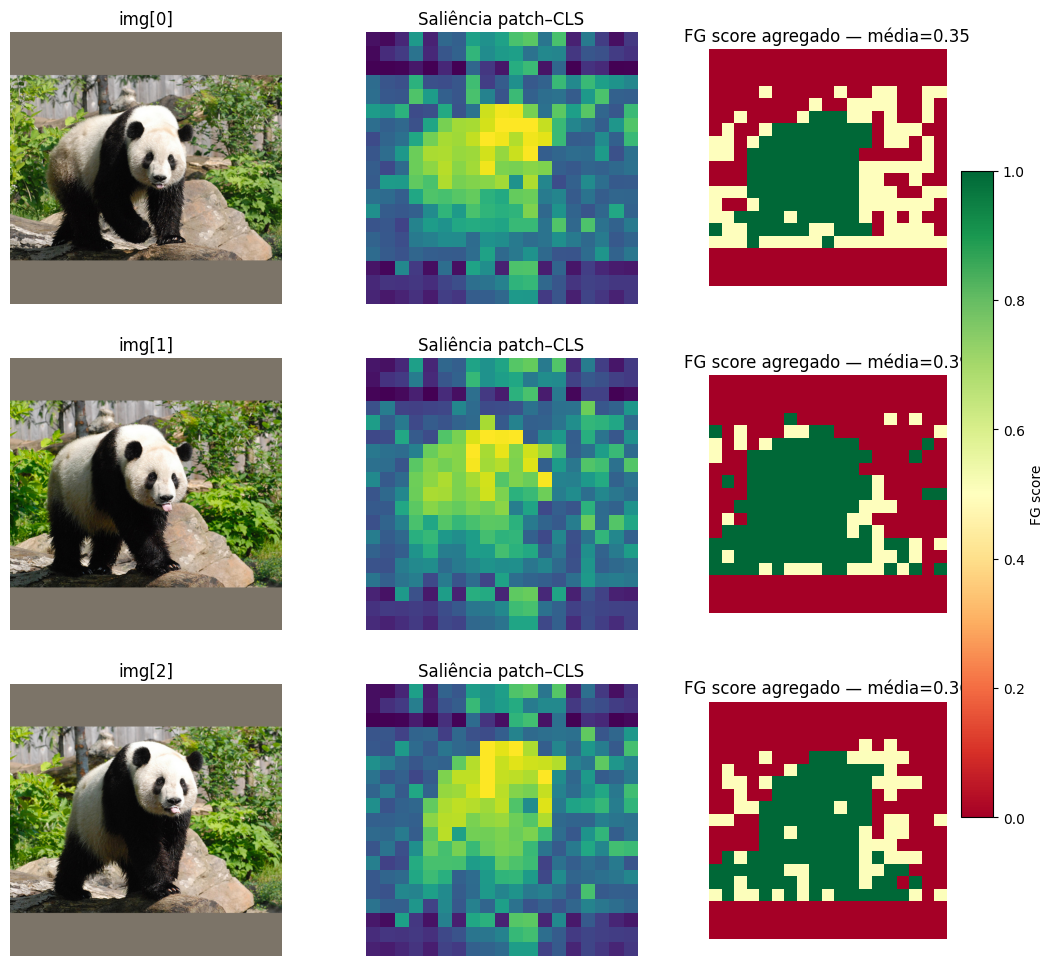

In [21]:
fig, axes = plt.subplots(N, 3, figsize=(13, 4 * N), squeeze=False)
for i in range(N):
    axes[i, 0].imshow(canvases[i]); axes[i, 0].set_title(f"img[{i}]")
    axes[i, 1].imshow(cls_saliency_2d[i], cmap="viridis", vmin=vmin, vmax=vmax,
                      interpolation="nearest")
    axes[i, 1].set_title("Saliência patch–CLS")
    score_view = axes[i, 2].imshow(fg_scores_2d[i], cmap="RdYlGn", vmin=0, vmax=1,
                                   interpolation="nearest")
    axes[i, 2].set_title(f"FG score agregado — média={fg_scores[i].mean():.2f}")
    for ax in axes[i]: ax.axis("off")
fig.colorbar(score_view, ax=axes[:, 2], shrink=.7, label="FG score")
plt.show()



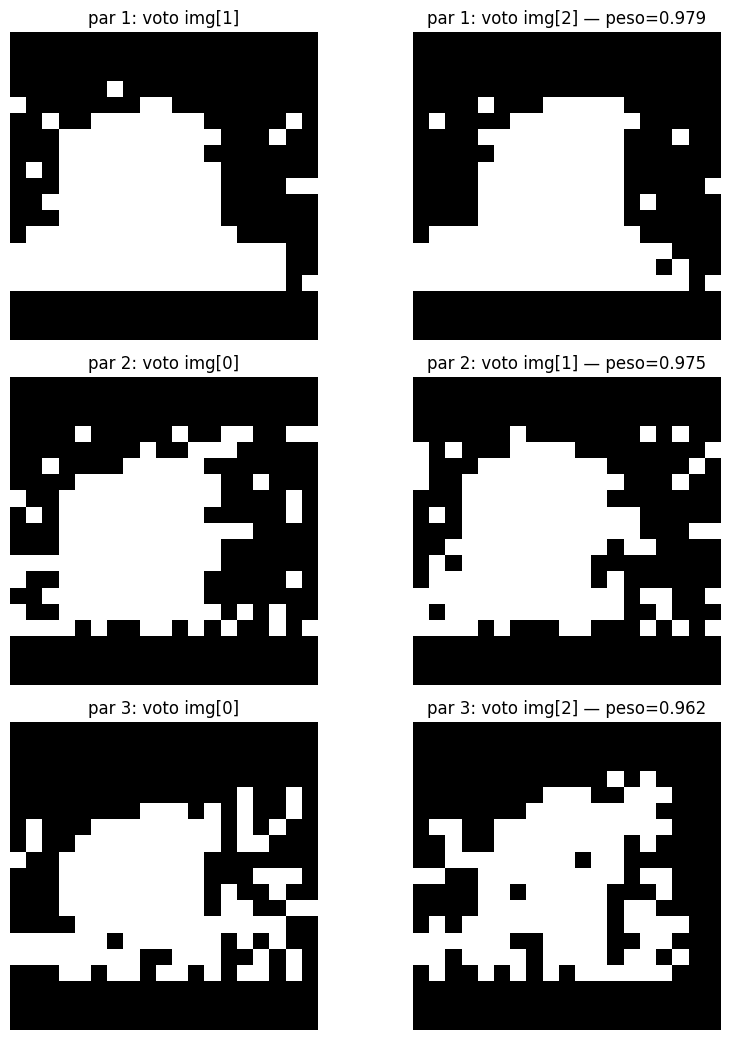

In [22]:
fig, axes = plt.subplots(K, 2, figsize=(9, 3.5 * K), squeeze=False)
for k, (i, j, sim) in enumerate(top_pairs):
    axes[k, 0].imshow(pair_votes[k, i].reshape(H_p, W_p), cmap="gray", vmin=0, vmax=1)
    axes[k, 0].set_title(f"par {k+1}: voto img[{i}]")
    axes[k, 1].imshow(pair_votes[k, j].reshape(H_p, W_p), cmap="gray", vmin=0, vmax=1)
    axes[k, 1].set_title(f"par {k+1}: voto img[{j}] — peso={max(sim,0):.3f}")
    for ax in axes[k]: ax.axis("off")
plt.tight_layout()



## Passo 10 — salvar o artefato didático

Com `PATCH_STRIDE = 1`, as dimensões correspondem à resolução integral da E2.
Com stride maior, o arquivo é apenas didático e não deve ser entregue à E3 do
pipeline real.



In [23]:
output_path = Path("correspondence_notebook.npz")
np.savez_compressed(
    output_path,
    fg_scores=fg_scores,
    fg_scores_2d=fg_scores_2d,
    cls_sim_matrix=cls_sim,
    top_pairs=np.asarray(top_pairs),
    pair_votes=pair_votes,
    cls_saliency=cls_saliency,
    patch_grid=np.asarray((H_p, W_p)),
    image_paths=np.asarray([str(p) for p in image_paths]),
    patch_stride=np.asarray(PATCH_STRIDE),
    orientation=np.asarray(ORIENTATION),
    degree_alpha=np.asarray(DEGREE_ALPHA, dtype=np.float32),
)

saved = np.load(output_path, allow_pickle=True)
print("Salvo em:", output_path.resolve())
for key in saved.files:
    value = saved[key]
    print(f"  {key:18s} shape={value.shape!s:16s} dtype={value.dtype}")


Salvo em: /mnt/e/github/cosegmentation/study/correspondence_notebook.npz
  fg_scores          shape=(3, 361)         dtype=float32
  fg_scores_2d       shape=(3, 19, 19)      dtype=float32
  cls_sim_matrix     shape=(3, 3)           dtype=float32
  top_pairs          shape=(3, 3)           dtype=float64
  pair_votes         shape=(3, 3, 361)      dtype=float32
  cls_saliency       shape=(3, 361)         dtype=float32
  patch_grid         shape=(2,)             dtype=int64
  image_paths        shape=(3,)             dtype=<U40
  patch_stride       shape=()               dtype=int64
  orientation        shape=()               dtype=<U7
  degree_alpha       shape=()               dtype=float32


## Mapa mental final

```text
features.npz
   ├── CLS ──→ similaridade global ──→ seleção dos pares
   └── patches
         ├── patch ↔ CLS ────────────→ saliência para orientar o corte (orientation='cls')
         └── patch ↔ patch
                   ↓
     [opcional] excluir patches de padding (content_mask)
                   ↓
            grafo combinado do par
                   ↓
     [opcional] reponderação por grau (degree_alpha)
                   ↓
         Laplaciano + vetor de Fiedler
                   ↓
     voto FG/BG por par (orientation='cls' ou 'spatial')
                   ↓
        média ponderada entre pares
                   ↓
             fg_scores (N, P)
                   ↓
        [fora deste notebook] E2B — supressão adaptativa
        de background recorrente, se E2_BG_SUPPRESSION != none
```

A E2 não encontrou ainda contornos em nível de pixel. Ela produziu evidências
cross-image, em resolução de patches, sobre quais regiões podem pertencer ao
objeto compartilhado.

## Questões críticas para observar

- O CLS realmente escolheu os pares mais úteis?
- As melhores correspondências locais ligam partes do mesmo objeto?
- O Fiedler separou objeto e fundo ou apenas regiões visualmente diferentes?
- A saliência CLS orientou corretamente os dois lados — ou a heurística
  `spatial` (default real da pipeline) discordou dela no bloco "Extra"?
  Divergência grande é sinal de que vale conferir manualmente qual dos dois
  lados é de fato o objeto nessa coleção.
- **O padding recebeu votos consistentes por aparecer em todas as imagens?**
  Sem `content_mask`, sim — é exatamente o vazamento que o bloco "Extra"
  mediu diretamente (contagem de patches de padding votados FG). Com a
  máscara ligada (padrão da pipeline e deste notebook a partir do Passo 9),
  não: esses patches são excluídos do grafo e o voto final é forçado a 0.
- A votação entre pares tornou o resultado mais estável ou reforçou um erro?
- `fg_scores` daqui bate, em espírito, com o que `step2_correspondence.py`
  produziria com as mesmas imagens e `TOP_K`/`TEMPERATURE`/`ORIENTATION`/
  `DEGREE_ALPHA` — mas não pixel-a-pixel, porque `PATCH_STRIDE` reamostra a
  grade. Para comparar números de verdade com uma classe do iCoseg, rode o
  script com `--visualize` e compare com `PATCH_STRIDE = 1`.
